# 11. Очереди, длительная миграция и сравнение на новых кластерах

Продолжение экспериментов после методологического аудита. Полный отчёт: V2_RESULTS.md. Здесь используются сохранённые результаты; повторного подбора по holdout нет. Числа — модельные затраты, не деньги или измеренный SLA.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
r=Path('v2_results')
display(json.loads(Path('v2/protocol.json').read_text()))
display(pd.read_csv(r/'report/budgets.csv'))

{'version': '2.0',
 'status': 'Protocol before holdout download/evaluation; cluster7 entirely development because already viewed',
 'holdout_clusters': [10, 26, 45],
 'choice_reason': 'Three small files (11,13,18 MB) selected by archive size, not policy performance',
 'holdout_calibration_slots': [0, 96],
 'holdout_scored_slots': [96, 672],
 'unsupported_operations': 'Reject cluster and report exclusion; do not choose a replacement based on results',
 'development_training_windows': [[96, 192], [192, 288], [288, 384]],
 'development_validation_windows': [[384, 480], [480, 576], [576, 672]],
 'development_capacity_calibration': [96, 384],
 'initial_state': 'All policies start with 4 shards, identical trace-derived inventory, empty service queue, no active migration. This models an idle queue at deployment; not continuous production state.',
 'work_scenario': 'get=1, set=2, plus reported key+value bytes/4096; not measured CPU costs',
 'capacity_scenario': 'mean incoming work/(4*0.65) on 

,kind,runs,transitions,seconds
0,dqn_continuous,12,92160,44.787323
1,dqn_matched,12,92160,46.570197
2,q,12,92160,44.297935


## Выбор по development
Три validation-дня и независимые инициализации. Дискретные признаки одинаковы у Q и DQN_matched. Для развёртывания заранее указан seed7; выбор seed по holdout запрещён.

In [2]:
display(json.loads((r/'selection.json').read_text()))
v=pd.read_csv(r/'validation.csv')
display(v.groupby(['kind','candidate'])[['cost','queue_slots']].mean())

{'q': {'candidate': 3,
  'seed': 7,
  'path': 'q_3_s7.npz',
  'validation_cost': 29237.88908465792},
 'dqn_matched': {'candidate': 3,
  'seed': 7,
  'path': 'dqn_matched_3_s7.npz',
  'validation_cost': 7225.0718334203675},
 'dqn_continuous': {'candidate': 3,
  'seed': 7,
  'path': 'dqn_continuous_3_s7.npz',
  'validation_cost': 7213.1944181003955},
 'threshold': {'up': 0.9,
  'down': 0.4,
  'validation_cost': 3952.487395924642,
  'search_seconds': 6.19046104200001},
 'fixed_target': {'target': 8.0, 'validation_cost': 4022.7075570724705}}

cost  queue_slots
kind           candidate                           
dqn_continuous 0          13641.502234    44.333333
               1          15645.226151    47.777778
               2          11220.566327    44.333333
               3           7213.194418    37.444444
dqn_matched    0          13641.502234    44.333333
               1           7992.262899    47.555556
               2          13641.502234    44.333333
               3           7225.071833    31.666667
q              0          43603.960685    76.444444
               1          33609.861002    87.000000
               2          32709.277330    75.666667
               3          29237.889085    75.111111

## Новый holdout
Три кластера выбраны по размеру файлов до скачивания. Первые 24 часа — только калибровка среды; следующие 144 часа — оценка. Модели заморожены до открытия файлов. Никаких доверительных интервалов по 15-минутным интервалам как независимым примерам.

,cluster,strategy,cost,server_cost,transfer_cost,queue_cost,queue_slots,queue_work_area,terminal_queue,terminal_transfer,moved_mb,migration_slots,migrations_started,migrations_completed,hot_key_slots
0,26,q_seed7,106819.226905,2879.0,287.500000,102593.325595,545,7.050540e+06,19011.669596,5.955933e+07,21.875552,575,1,0,5
1,26,q_seed42,106785.460389,2877.0,286.500000,102568.349980,541,7.048824e+06,19011.669596,5.911871e+07,21.799463,573,1,0,5
2,26,q_seed123,107667.130280,2304.0,288.000000,102593.632815,546,7.050561e+06,19011.669596,1.677650e+08,21.913596,576,1,0,5
3,26,dqn_matched_seed7,106823.402205,2880.0,288.000000,102593.632815,546,7.050561e+06,19011.669596,5.973952e+07,21.913596,576,1,0,5
4,26,dqn_matched_seed42,106823.402205,2880.0,288.000000,102593.632815,546,7.050561e+06,19011.669596,5.973952e+07,21.913596,576,1,0,5
5,26,dqn_matched_seed123,106823.402205,2880.0,288.000000,102593.632815,546,7.050561e+06,19011.669596,5.973952e+07,21.913596,576,1,0,5
6,26,dqn_continuous_seed7,100622.750421,2813.0,254.500000,96596.305963,512,6.638406e+06,18217.460449,5.279501e+07,19.364619,509,1,0,5
7,26,dqn_continuous_seed42,106823.402205,2880.0,288.000000,102593.632815,546,7.050561e+06,19011.669596,5.973952e+07,21.913596,576,1,0,5
8,26,dqn_continuous_seed123,4687.367875,2304.0,0.000000,2383.367875,162,1.637926e+05,0.000000,0.000000e+00,0.000000,0,0,0,5
9,26,threshold,106785.460389,2877.0,286.500000,102568.349980,541,7.048824e+06,19011.669596,5.911871e+07,21.799463,573,1,0,5


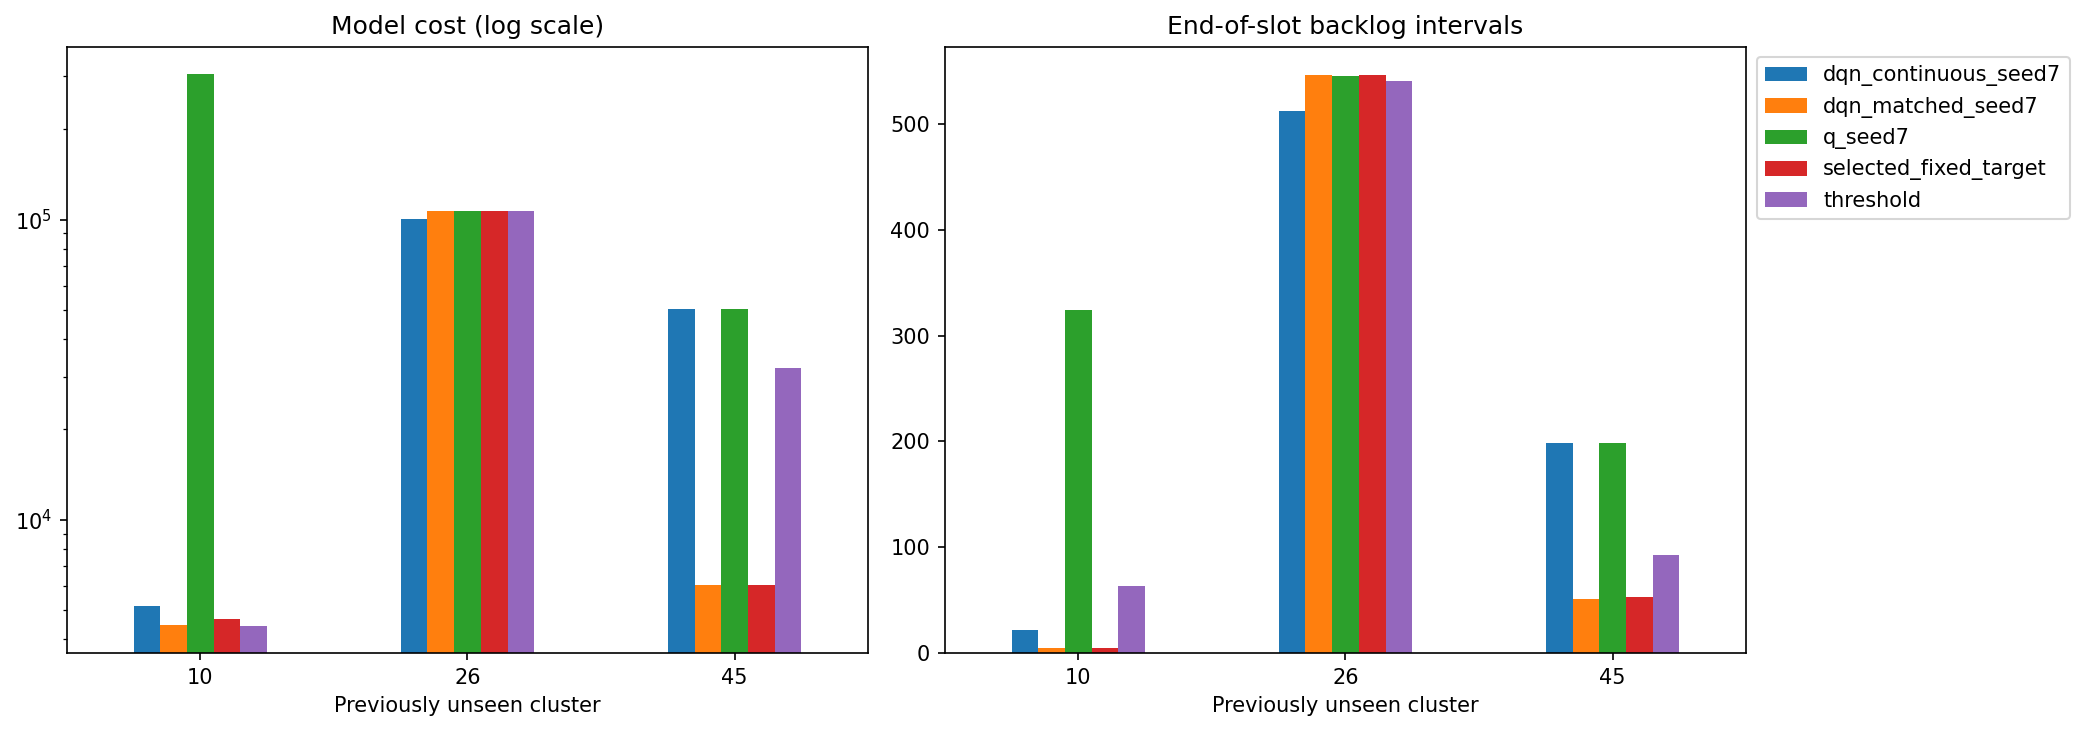

In [3]:
display(pd.read_csv(r/'report/combined_comparison.csv'))
display(Image(filename=str(r/'report/holdout.png')))

## Миграция и накопленная очередь
Проверяем сохранение работы и байтов на реальной траектории. Очередь не исчезает при cutover. Непогашенные обязательства в конце видны отдельно.

In [4]:
f=next((r/'holdout').glob('cluster*_threshold.csv'))
t=pd.read_csv(f)
import numpy as np
np.testing.assert_allclose(t.queue_before+t.incoming_work,t.served_work+t.queue_after,rtol=1e-9,atol=1e-6)
np.testing.assert_allclose(t.transfer_before+t.dirty_bytes,t.transferred_bytes+t.transfer_remaining,rtol=1e-9,atol=1e-6)
display(t[['slot','old_shards','shards','target','migration_active','transferred_bytes','transfer_remaining','queue_after']].head(24))

,slot,old_shards,shards,target,migration_active,transferred_bytes,transfer_remaining,queue_after
0,96,4,4,5,1,2.444250e+06,3.612080e+06,789.030374
1,97,4,4,5,1,2.444250e+06,1.820742e+06,1184.242876
2,98,4,4,5,1,2.444250e+06,8.404688e+03,1510.356258
3,99,4,5,5,1,5.373457e+05,0.000000e+00,868.516396
4,100,5,5,6,1,2.444250e+06,2.407005e+06,97.057114
5,101,5,5,6,1,2.444250e+06,4.146171e+05,0.000000
6,102,5,6,6,1,7.687541e+05,0.000000e+00,0.000000
7,103,6,6,6,0,0.000000e+00,0.000000e+00,0.000000
8,104,6,6,6,0,0.000000e+00,0.000000e+00,0.000000
9,105,6,6,6,0,0.000000e+00,0.000000e+00,0.000000


## Горячие ключи, сдвиг и устойчивость
Горячий ключ определяется по собственной нагрузке > мощности сервера; это отличается от коллизий JCH. Таблица чувствительности меняет мощность и полосу отдельно, без перенастройки политики.

In [5]:
display(pd.read_csv(r/'report/daily_diagnostics.csv'))
display(pd.read_csv(r/'report/sensitivity.csv'))

,cluster,day,hot_key_over_capacity_slots,mean_work,mean_inventory_mb
0,26,2,0,3477.854970,0.247988
1,26,3,0,3420.493080,0.300660
2,26,4,0,3706.620427,0.471812
3,26,5,1,4073.074053,0.469228
4,26,6,3,3673.225255,0.405439
5,26,7,1,3519.859161,0.456413
6,10,2,0,3540.698792,19.977043
7,10,3,0,3583.382963,20.053341
8,10,4,0,3533.648903,19.697355
9,10,5,0,3666.510180,21.030561


,cluster,parameter,factor,strategy,cost,server_cost,transfer_cost,queue_cost,queue_slots,queue_work_area,terminal_queue,terminal_transfer,moved_mb,migration_slots,migrations_started,migrations_completed,hot_key_slots
0,26,capacity,0.5,q_seed7,6.874091e+06,2304.0,288.000000,6.845054e+06,576,2.352070e+08,8.329224e+05,1.677650e+08,21.913596,576,1,0,14
1,26,capacity,0.5,dqn_matched_seed7,6.873247e+06,2880.0,288.000000,6.845054e+06,576,2.352070e+08,8.329224e+05,5.973952e+07,21.913596,576,1,0,14
2,26,capacity,0.5,dqn_continuous_seed7,6.864012e+06,2879.0,287.500000,6.835838e+06,576,2.348903e+08,8.323727e+05,5.955933e+07,21.875552,575,1,0,14
3,26,capacity,0.5,threshold,6.873247e+06,2880.0,288.000000,6.845054e+06,576,2.352070e+08,8.329224e+05,5.973952e+07,21.913596,576,1,0,14
4,26,capacity,0.5,selected_fixed_target,6.873247e+06,2880.0,288.000000,6.845054e+06,576,2.352070e+08,8.329224e+05,5.973952e+07,21.913596,576,1,0,14
5,26,bandwidth,0.5,q_seed7,1.068192e+05,2879.0,143.750000,1.025933e+05,545,7.050540e+06,1.901167e+04,7.049711e+07,10.937776,575,1,0,5
6,26,bandwidth,0.5,dqn_matched_seed7,1.068234e+05,2880.0,144.000000,1.025936e+05,546,7.050561e+06,1.901167e+04,7.069631e+07,10.956798,576,1,0,5
7,26,bandwidth,0.5,dqn_continuous_seed7,1.006228e+05,2813.0,127.250000,9.659631e+04,512,6.638406e+06,1.821746e+04,6.247732e+07,9.682309,509,1,0,5
8,26,bandwidth,0.5,threshold,1.067855e+05,2877.0,143.250000,1.025683e+05,541,7.048824e+06,1.901167e+04,7.001844e+07,10.899731,573,1,0,5
9,26,bandwidth,0.5,selected_fixed_target,1.068234e+05,2880.0,144.000000,1.025936e+05,546,7.050561e+06,1.901167e+04,7.069631e+07,10.956798,576,1,0,5


## Действия агента
Это наблюдаемые ассоциации признаков с командой, не доказательство причин решения и не глобальное правило. Команда во время незавершённой миграции игнорируется средой.

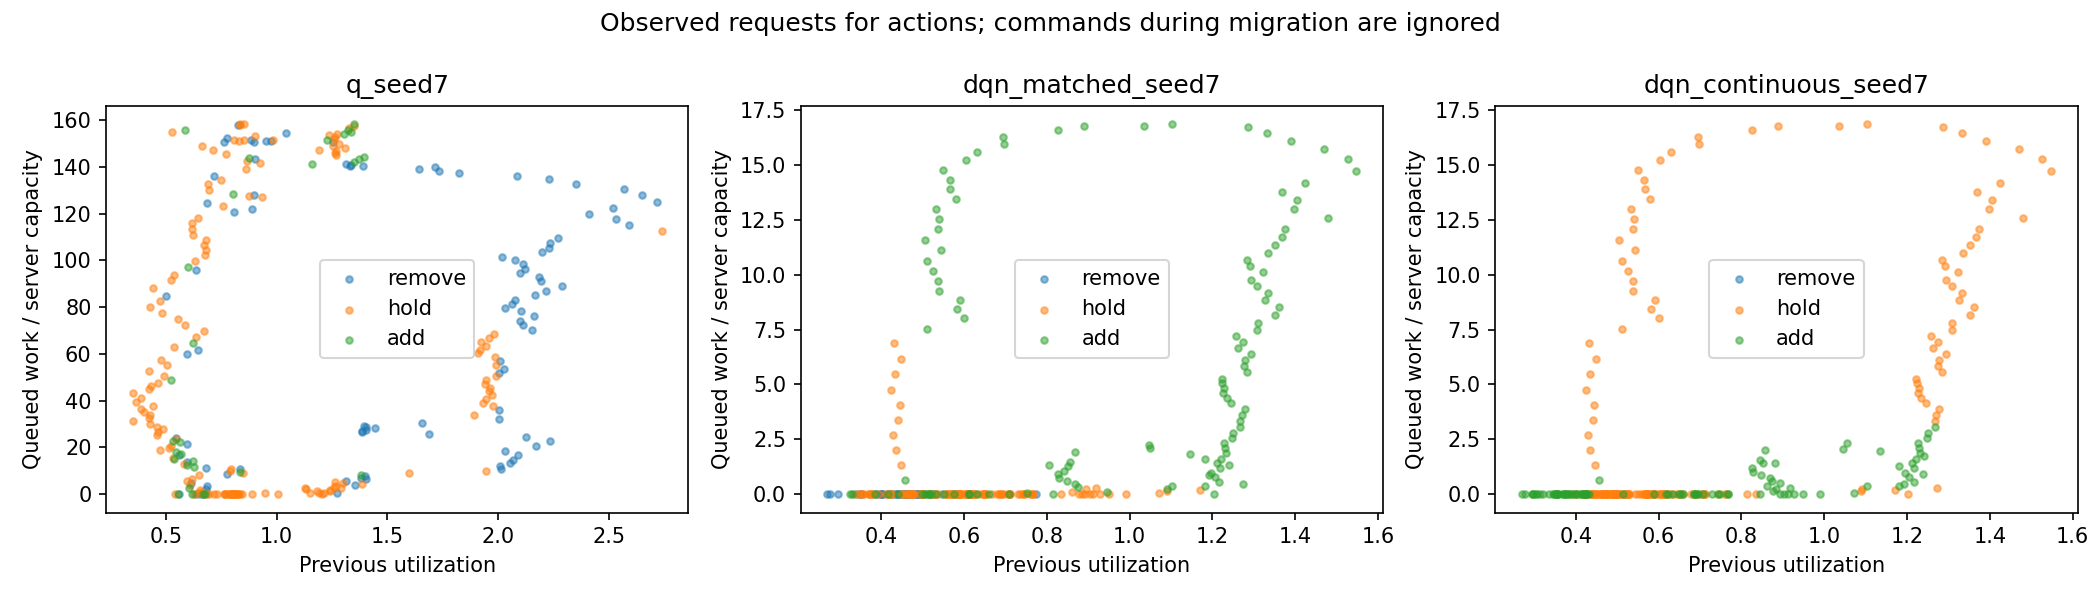

In [6]:
display(Image(filename=str(r/'report/actions.png')))

## Ограничения
Fluid-очередь не измеряет latency; сценарные веса операций и полоса не заменяют замеры. Нет реплик, eviction, реальной сети или ClickHouse. Три кластера недостаточны для сильного вывода об обобщении. Неудачные результаты сохранены; после этого отчёта данные считаются просмотренными.

## Отдельно: защита переноса после просмотра holdout
Эта диагностическая доработка использует только прошлые записи, но придумана после результата cluster26. Её эффект не является независимой оценкой. Она отклоняет потенциально незавершаемые миграции; активную миграцию не отменяет.

In [7]:
display(pd.read_csv(r/'post_holdout_guard/comparison.csv'))

,cluster,strategy,rejections,cost,server_cost,transfer_cost,queue_cost,queue_slots,queue_work_area,terminal_queue,terminal_transfer,moved_mb,migration_slots,migrations_started,migrations_completed,hot_key_slots
0,10,q_seed7,0,305056.465581,2608.0,45.427296,302403.038285,324,1.856678e+07,0.000000,0.0,222.071378,101,35,35,0
1,10,dqn_matched_seed7,0,4465.686211,4318.0,75.220627,72.465584,5,4.449203e+03,0.000000,0.0,367.716101,203,170,170,0
2,10,dqn_continuous_seed7,0,5166.906415,4177.0,5.717366,984.189048,22,6.042671e+04,0.000000,0.0,27.949351,14,5,5,0
3,10,threshold,0,4446.702679,3099.0,58.886792,1288.815887,63,7.913003e+04,0.000000,0.0,287.868133,145,64,64,0
4,10,selected_fixed_target,0,4664.602643,4588.0,4.137059,72.465584,5,4.449203e+03,0.000000,0.0,20.224018,11,4,4,0
5,26,q_seed7,282,4687.367875,2304.0,0.000000,2383.367875,162,1.637926e+05,0.000000,0.0,0.000000,0,0,0,5
6,26,dqn_matched_seed7,431,4687.367875,2304.0,0.000000,2383.367875,162,1.637926e+05,0.000000,0.0,0.000000,0,0,0,5
7,26,dqn_continuous_seed7,43,4687.367875,2304.0,0.000000,2383.367875,162,1.637926e+05,0.000000,0.0,0.000000,0,0,0,5
8,26,threshold,241,4687.367875,2304.0,0.000000,2383.367875,162,1.637926e+05,0.000000,0.0,0.000000,0,0,0,5
9,26,selected_fixed_target,576,4687.367875,2304.0,0.000000,2383.367875,162,1.637926e+05,0.000000,0.0,0.000000,0,0,0,5
